# LJ structure and dynamics

Original educational notebook. Read the linked course chapters. All synthetic models are labeled; no material property is inferred from a short run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p/'scripts/numerics.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Extract the complete repository, then open this notebook from its root or notebooks folder.')
sys.path.insert(0, str(ROOT))
np.set_printoptions(precision=5)


## Execute a small diagnostic
108 particles; force-shifted LJ cutoff 2σ; NVT preparation and NVE production. This is not a converged diffusion calculation.

Frames, particles: (151, 108)


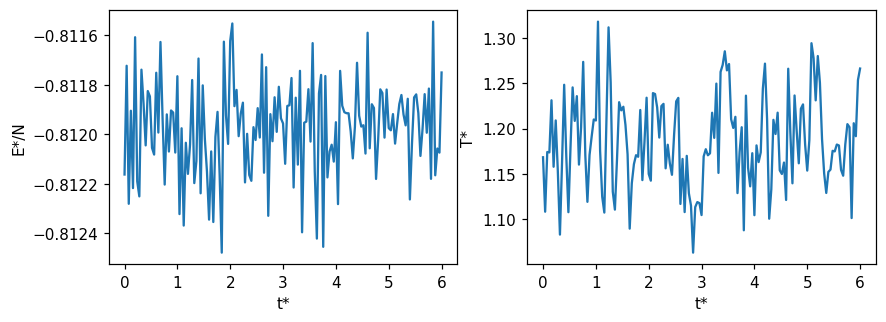

In [2]:
from scripts.numerics import run_lj,rdf,msd,vacf,diffusion_slope
d=run_lj(equil=500,steps=1500,stride=10,seed=2026)
x=d['positions'];box=float(d['box']);th=d['thermo']
print('Frames, particles:',x.shape[:2])
fig,ax=plt.subplots(1,2,figsize=(9,3))
ax[0].plot(th[:,0],th[:,3]);ax[0].set(xlabel='t*',ylabel='E*/N')
ax[1].plot(th[:,0],th[:,4]);ax[1].set(xlabel='t*',ylabel='T*')
plt.show()

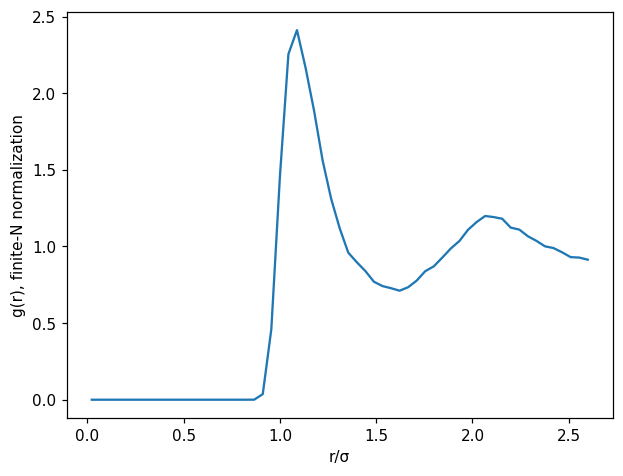

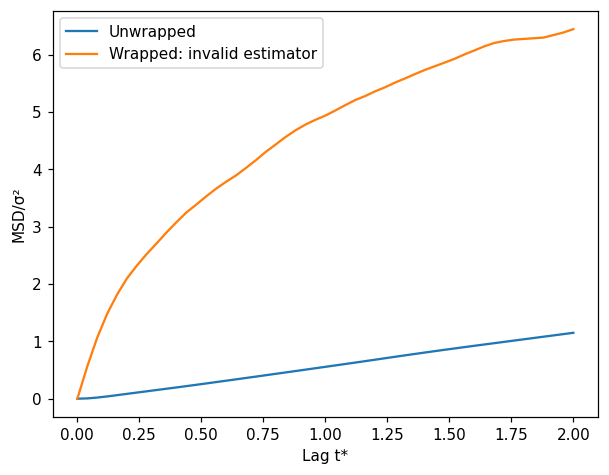

In [3]:
r,g=rdf(x,box,np.linspace(0,box/2,60))
plt.plot(r,g);plt.xlabel('r/σ');plt.ylabel('g(r), finite-N normalization');plt.show()
lag=np.arange(51)*float(d['dt_saved'])
m=msd(x,50);wrong=msd(x%box,50)
plt.plot(lag,m,label='Unwrapped')
plt.plot(lag,wrong,label='Wrapped: invalid estimator')
plt.xlabel('Lag t*');plt.ylabel('MSD/σ²');plt.legend();plt.show()

**Exercise:** inspect log–log MSD and longer independent runs before choosing a diffusive interval. Do not publish a slope from the arbitrary interval below.

Illustrative slope estimate, not converged D: 0.10113976294638811


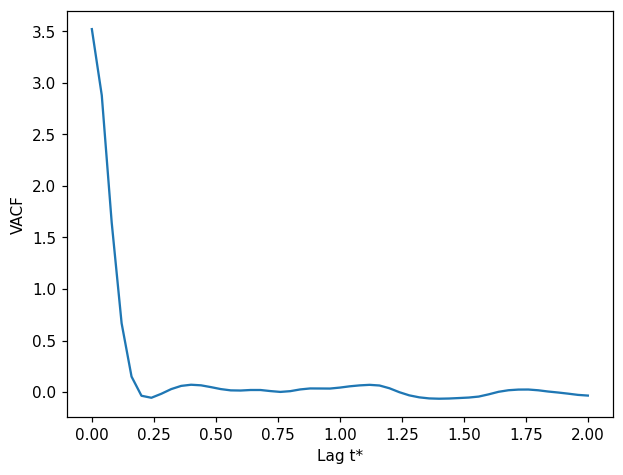

In [4]:
# Arithmetic demonstration only; the physical fit interval is NOT validated.
D,intercept=diffusion_slope(lag,m,lag[20],lag[45],dimensions=3)
print('Illustrative slope estimate, not converged D:',D)
c=vacf(d['velocities'],50)
plt.plot(lag,c);plt.xlabel('Lag t*');plt.ylabel('VACF');plt.show()

Repeat with another seed and cell size. Compare block estimates and explain why MSD-lag regression residuals underestimate trajectory uncertainty.